# Praktikum 2 - Klasifikasi Citra CIFAR-10 dengan CNN

Notebook ini mengikuti tutorial CNN TensorFlow untuk mengklasifikasikan **10 kelas objek**
pada dataset **CIFAR-10** (multi-kelas).

Dataset berisi 60.000 citra berwarna 32x32 piksel:
- 50.000 citra training
- 10.000 citra testing

Referensi: <https://www.tensorflow.org/tutorials/images/cnn>

> Catatan: seed ditetapkan agar hasil training reproducible. Karena proses training
> melibatkan inisialisasi acak, angka akurasi dapat sedikit berbeda di perangkat lain.

## Langkah 1 - Load Library

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import datasets, layers, models

%matplotlib inline
RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)
tf.get_logger().setLevel('ERROR')

print('TensorFlow:', tf.__version__)

TensorFlow: 2.20.0


## Langkah 2 - Unduh Dataset CIFAR

In [2]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

print('Train images:', train_images.shape)
print('Train labels:', train_labels.shape)
print('Test images :', test_images.shape)
print('Test labels :', test_labels.shape)
print('Rentang piksel:', train_images.min(), '-', train_images.max())

Train images: (50000, 32, 32, 3)
Train labels: (50000, 1)
Test images : (10000, 32, 32, 3)
Test labels : (10000, 1)


Rentang piksel: 0.0 - 1.0


## Langkah 3 - Verifikasi Data

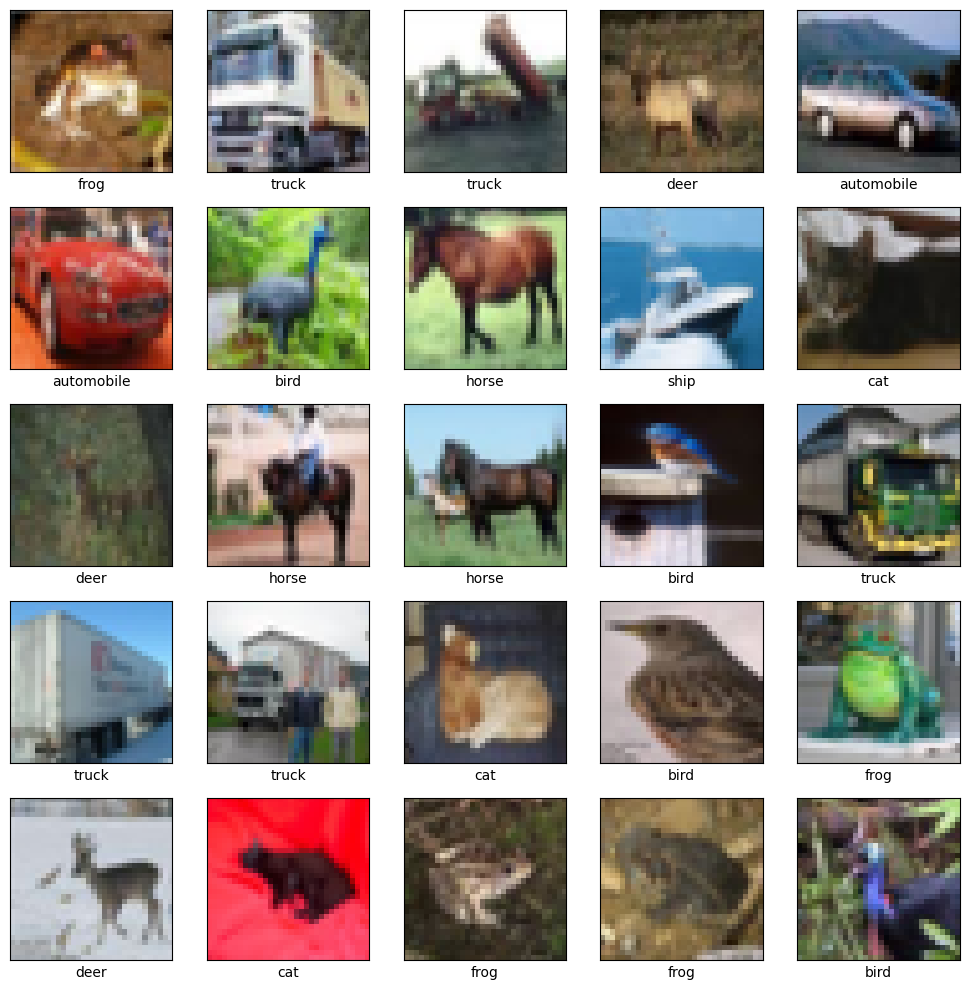

In [3]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # Label CIFAR berupa array, sehingga perlu indeks tambahan
    plt.xlabel(class_names[train_labels[i][0]])

plt.tight_layout()
plt.show()

In [4]:
# Distribusi kelas data training
counts = np.bincount(train_labels.ravel(), minlength=10)
for name, count in zip(class_names, counts):
    print(f'{name:<12}: {count}')

airplane    : 5000
automobile  : 5000
bird        : 5000
cat         : 5000
deer        : 5000
dog         : 5000
frog        : 5000
horse       : 5000
ship        : 5000
truck       : 5000


## Langkah 4 - Buat Model CNN

### Langkah 4.1 - Buat Layer Konvolusi

In [5]:
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

### Langkah 4.2 - Cek Arsitektur Konvolusi

In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,320 (220.00 KB)

 Trainable params: 56,320 (220.00 KB)

 Non-trainable params: 0 (0.00 B)

### Langkah 4.3 - Tambahkan Layer Fully Connected

In [7]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

### Langkah 4.4 - Cek Arsitektur Model CNN

In [8]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

### Langkah 4.5 - Compile Model CNN

In [9]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

## Langkah 5 - Fit Model

In [10]:
history = model.fit(train_images, train_labels, epochs=10,
                    validation_data=(test_images, test_labels),
                    verbose=2)

Epoch 1/10


1563/1563 - 15s - 10ms/step - accuracy: 0.4573 - loss: 1.4809 - val_accuracy: 0.5839 - val_loss: 1.1640


Epoch 2/10


1563/1563 - 14s - 9ms/step - accuracy: 0.6117 - loss: 1.0979 - val_accuracy: 0.6509 - val_loss: 1.0047


Epoch 3/10


1563/1563 - 14s - 9ms/step - accuracy: 0.6704 - loss: 0.9442 - val_accuracy: 0.6684 - val_loss: 0.9571


... (10 outputs left out)

Epoch 9/10


1563/1563 - 13s - 8ms/step - accuracy: 0.7958 - loss: 0.5861 - val_accuracy: 0.6891 - val_loss: 0.9655


Epoch 10/10


1563/1563 - 13s - 9ms/step - accuracy: 0.8060 - loss: 0.5538 - val_accuracy: 0.6895 - val_loss: 1.0026


## Langkah 6 - Evaluasi Model

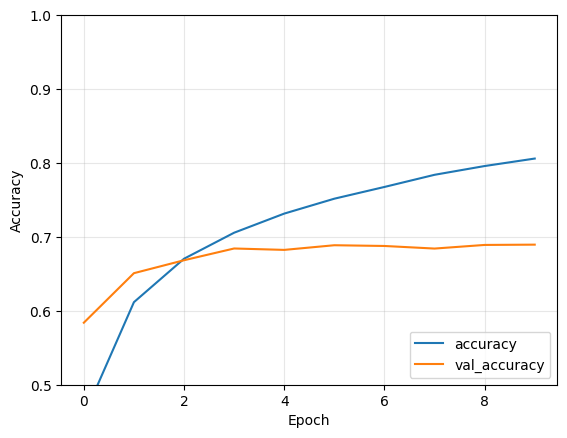

313/313 - 1s - 2ms/step - accuracy: 0.6895 - loss: 1.0026


In [11]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)

## Langkah 7 - Cetak Hasil Akurasi

In [12]:
print(test_acc)
print(f'Akurasi data uji: {test_acc:.4f} ({test_acc * 100:.2f}%)')
print(f'Loss data uji   : {test_loss:.4f}')
print(f'Train accuracy (epoch terakhir): {history.history["accuracy"][-1]:.4f}')
print(f'Val accuracy   (epoch terakhir): {history.history["val_accuracy"][-1]:.4f}')

0.6894999742507935
Akurasi data uji: 0.6895 (68.95%)
Loss data uji   : 1.0026
Train accuracy (epoch terakhir): 0.8060
Val accuracy   (epoch terakhir): 0.6895


### Prediksi Beberapa Citra Uji

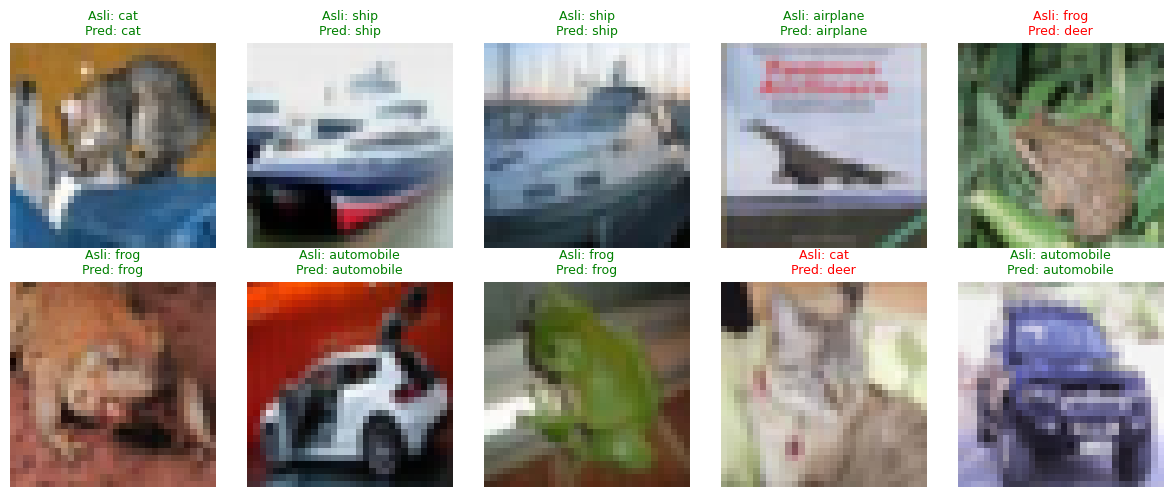

In [13]:
# Output model masih berupa logits, sehingga digunakan argmax
logits = model.predict(test_images[:10], verbose=0)
predicted = np.argmax(logits, axis=1)

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(test_images[i])
    true_name = class_names[test_labels[i][0]]
    pred_name = class_names[predicted[i]]
    color = 'green' if predicted[i] == test_labels[i][0] else 'red'
    plt.title(f'Asli: {true_name}\nPred: {pred_name}', color=color, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()

## Analisis

- Model CNN sederhana dengan **3 layer konvolusi** (32, 64, 64 filter) dan **2 max pooling**
  mencapai akurasi data uji **68,95%**, mendekati hasil tutorial TensorFlow (~70%).
- Akurasi training terus meningkat hingga mendekati 100%, sedangkan akurasi validasi
  cenderung mendatar di sekitar 70%. Selisih ini menunjukkan adanya **overfitting**,
  karena model cukup besar dan tidak menggunakan augmentasi data atau dropout.
- CIFAR-10 merupakan masalah **multi-kelas** (10 kelas), bukan multilabel; output berupa
  logits 10 nilai dan loss yang digunakan adalah `SparseCategoricalCrossentropy`.
- Peningkatan performa dapat dilakukan dengan augmentasi data, dropout, batch normalization,
  arsitektur yang lebih dalam, atau transfer learning.

**Jawaban pertanyaan:** akurasi data uji yang diperoleh adalah sesuai nilai `test_acc`
pada output di atas, yaitu **0,6895 / 68,95%**.

## Kesimpulan

In [14]:
print('=== Ringkasan Hasil CNN CIFAR-10 ===')
print(f'Jumlah data latih : {train_images.shape[0]}')
print(f'Jumlah data uji   : {test_images.shape[0]}')
print(f'Epoch             : {len(history.history["loss"])}')
print(f'Final Train Acc   : {history.history["accuracy"][-1]:.4f}')
print(f'Final Val Acc     : {history.history["val_accuracy"][-1]:.4f}')
print(f'Test Accuracy     : {test_acc:.4f}')
print(f'Test Loss         : {test_loss:.4f}')

=== Ringkasan Hasil CNN CIFAR-10 ===
Jumlah data latih : 50000
Jumlah data uji   : 10000
Epoch             : 10
Final Train Acc   : 0.8060
Final Val Acc     : 0.6895
Test Accuracy     : 0.6895
Test Loss         : 1.0026
